# Thermal phase curve

The thermal phase curve of a bare rock for the extended star (`"hyperillum"`) and the point source (`"naive"`): the temperature map, the light curve SPIDERMAN integrates from it, the occultation depth and brightness temperature, and where the two models differ. Reflected light is in `03_reflected_phase_curve.ipynb`, the sum of both in `04_full_phase_curve.ipynb`; speed and convergence in `validation/speed_accuracy.ipynb`.

In [1]:
import warnings
import matplotlib.pyplot as plt
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman
from hyperphase.phasecurve import custom_temperature_grid, thermal_PhaseCurve
from hyperphase.stellar import T_bright
from hyperphase.bands import filter_lambda, filter_loc
from hyperphase.defaults import DEFAULT_A_B, DEFAULT_U, DEFAULT_U_BOL
from hyperphase.targets import hi_planets_by_name
warnings.filterwarnings("ignore", message="Adding colorbar to a different Figure", module="fspiderman")   # raised by fspiderman's plot_quad, which attaches its colour bar through pyplot; the figure is drawn correctly

In [2]:
planet = hi_planets_by_name("TOI-2431 b")   # an archive planet or a curated entry (inputs/planets/curated_planets.csv)
u, u_bol = DEFAULT_U, DEFAULT_U_BOL   # transit and irradiance limb darkening
A_B = DEFAULT_A_B                     # Bond albedo: sets the temperature map

Instrument = "MIRI/LRS"
lambda_range, filter_path = filter_lambda(Instrument), filter_loc(Instrument)

## 1. Temperature map

`custom_temperature_grid` returns longitude and latitude [deg] and the equilibrium temperature [K] of every cell ($\varepsilon_{\rm bol}\,\sigma T^4 = (1 - A_B)\,I$), with the substellar point at (0°, 0°). The extended star heats a ring beyond the 90° terminator, where the point source leaves the surface at 0 K.

In [3]:
lo, la, temp_grid = custom_temperature_grid(planet, insolation_model = "hyperillum", u_bol=u_bol)

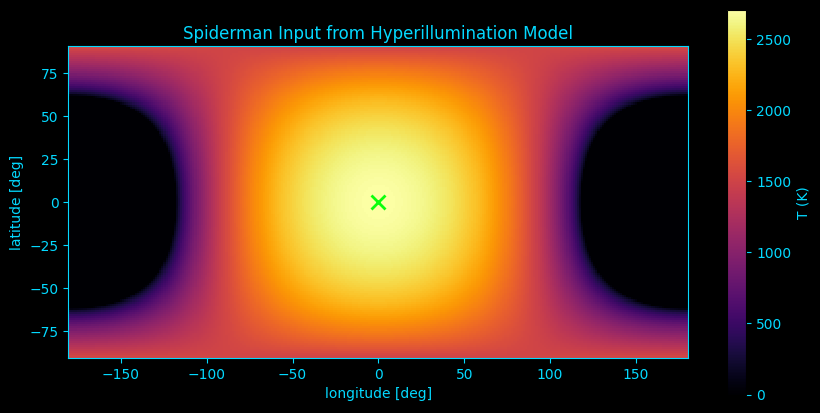

In [4]:
bg, tc = "black", "#04d9ff"   # same dark theme as plot_insolmap(..., theme='black')

fig, ax = plt.subplots(figsize=(10, 5), facecolor=bg)
im = ax.pcolormesh(lo, la, temp_grid, cmap=plt.cm.inferno, shading="auto")   # same colormap as plot_insolmap
ax.plot(0, 0, "x", color="#0cff0c", ms=10, mew=2)   # substellar point, same marker convention as spiderman's plot_square
ax.set_aspect("equal")
ax.set_facecolor(bg)
ax.set_xlabel("longitude [deg]", color=tc)
ax.set_ylabel("latitude [deg]", color=tc)
ax.tick_params(colors=tc)
for spine in ax.spines.values():
    spine.set_color(tc)

cbar = fig.colorbar(im, ax=ax)
cbar.ax.tick_params(colors=tc)
cbar.set_label("T (K)", color=tc)

ax.set_title("Spiderman Input from Hyperillumination Model", color=tc)
plt.show()

## 2. Light curve from the map

`thermal_PhaseCurve` builds the map itself for the given `insolation_model`, hands it to SPIDERMAN as a `direct_T` brightness map and returns the times [days], the flux relative to the star, the occultation depth [ppm] and SPIDERMAN's `ModelParams`.

In [5]:
t_hyperillum, thermal_phasecurve_hyperillum, thermal_fp_hyperillum, spider_params_hyperillum = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="hyperillum", filter_path=filter_path, A_B=A_B, u_bol=u_bol)
t_naive, thermal_phasecurve_naive, thermal_fp_naive, spider_params_naive = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, u_bol=u_bol)

**Brightness maps.** The planet as SPIDERMAN sees it at the phases 0 (transit), 0.25, 0.5 (full phase) and 0.75, for both models. The slight asymmetry at phase 0 comes from the inclination ($i < 90°$).

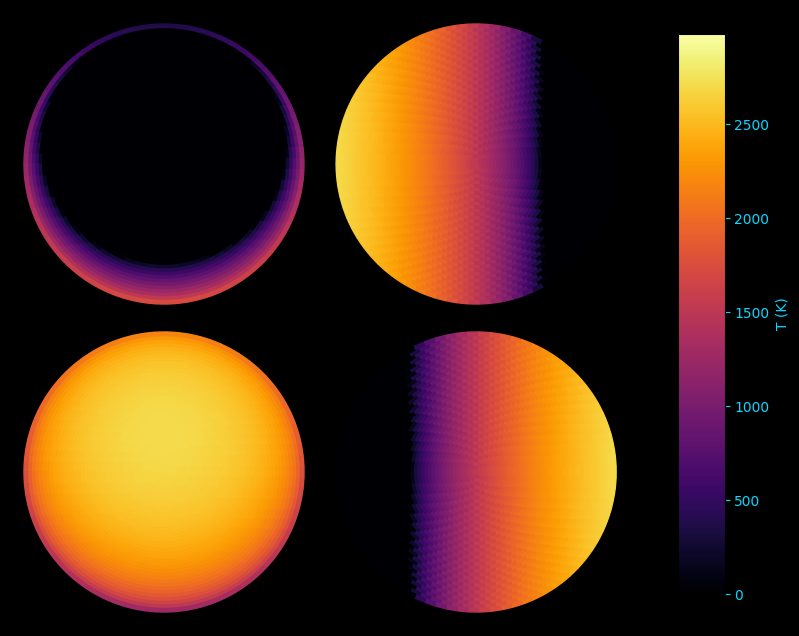

In [6]:
fig = spider_params_hyperillum.plot_quad(temp_map=True, theme="black")
plt.show()

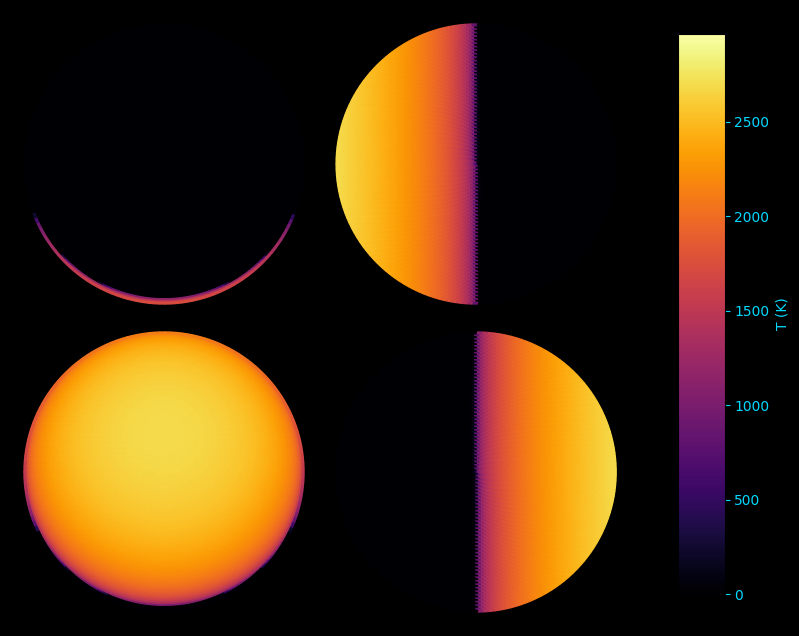

In [7]:
fig = spider_params_naive.plot_quad(temp_map=True, theme="black")
plt.show()

## 3. Phase curve, occultation depth and brightness temperature

The thermal phase curves of both models with transit and occultation, their occultation depths, and the dayside brightness temperature of each depth.

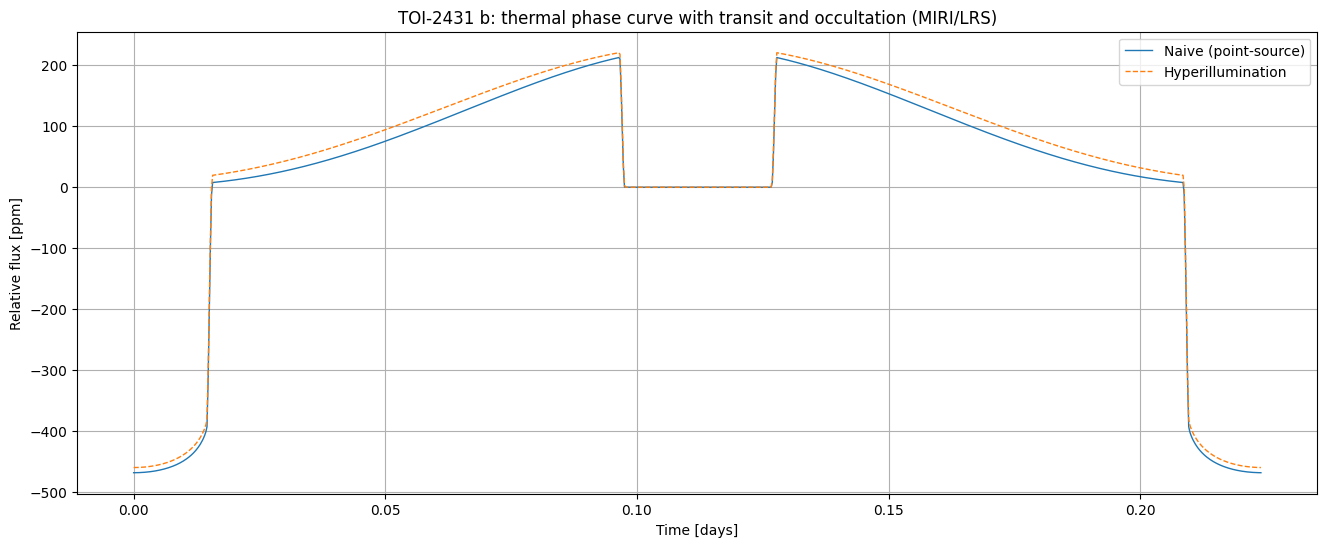

Occultation depth with Hyperillumination: 232.3 ppm
Occultation depth without Hyperillumination: 228.1 ppm


In [8]:
plt.figure(figsize=(16, 6))
plt.plot(t_naive, (thermal_phasecurve_naive - 1)*1e6, linewidth=1, label="Naive (point-source)")
plt.plot(t_hyperillum, (thermal_phasecurve_hyperillum - 1)*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel("Relative flux [ppm]")
plt.title(f"{planet.name}: thermal phase curve with transit and occultation ({Instrument})")
plt.legend()
plt.grid()
plt.show()

print(f"Occultation depth with Hyperillumination: {thermal_fp_hyperillum:.1f} ppm")
print(f"Occultation depth without Hyperillumination: {thermal_fp_naive:.1f} ppm")

In [9]:
# brightness temperature of the occultation depth: the blackbody temperature whose band flux gives that depth with this star
print(f"Dayside Brightness Temperature (hyperillumination): {T_bright(thermal_fp_hyperillum, planet, lambda_range, filter_path=filter_path):.0f} K")
print(f"Dayside Brightness Temperature (naive): {T_bright(thermal_fp_naive, planet, lambda_range, filter_path=filter_path):.0f} K")

Dayside Brightness Temperature (hyperillumination): 2376 K
Dayside Brightness Temperature (naive): 2347 K


## 4. Where the two models differ

The planet's thermal flux alone (no transit, no occultation) in both models and its difference: smallest near full phase, where the occultation depth is measured, and largest near quadrature, where the ring beyond the terminator faces the observer. The difference of the occultation depths is therefore a poor proxy for how well the models can be told apart.

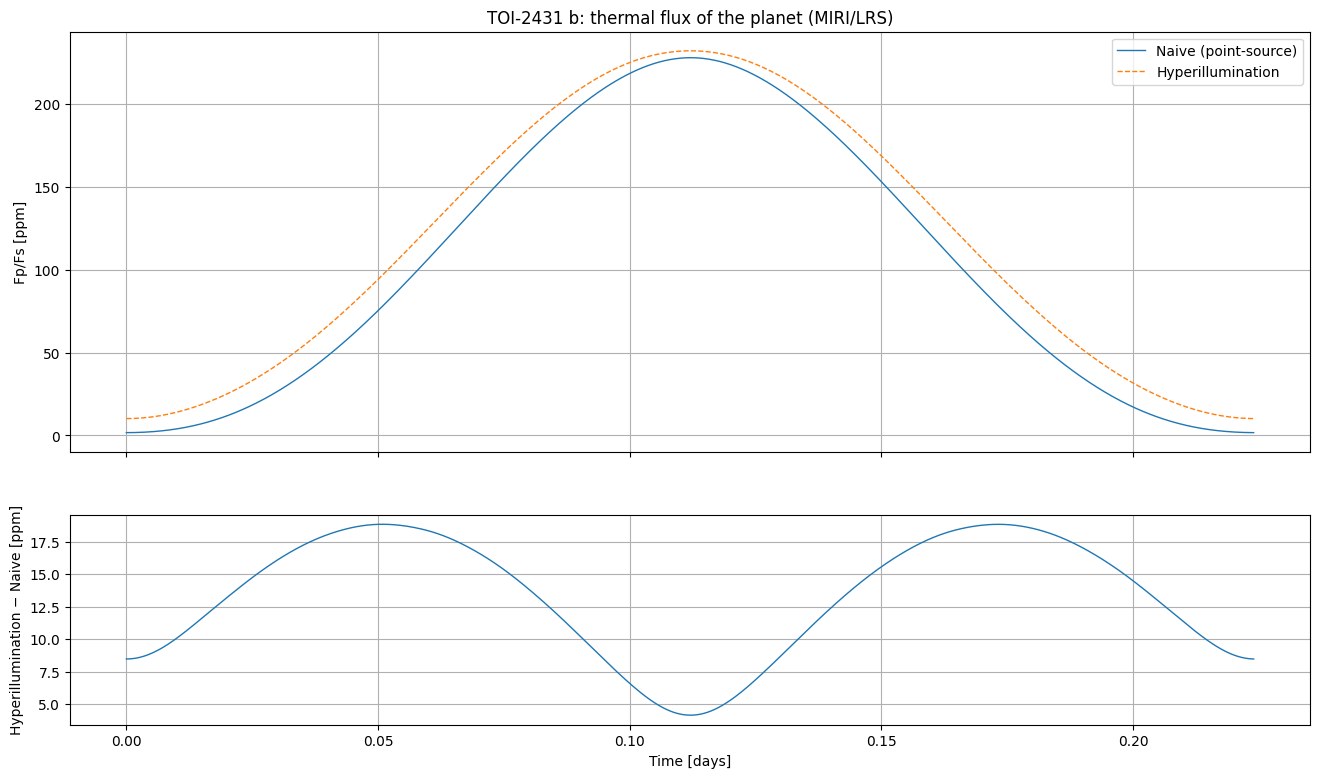

In [10]:
t_hyperillum, thermal_lightcurve_hyperillum, _, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="hyperillum", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False, u_bol=u_bol)
t_naive, thermal_lightcurve_naive, _, _ = thermal_PhaseCurve(planet, lambda_range, u=u, insolation_model="naive", filter_path=filter_path, A_B=A_B, include_transit=False, include_occultation=False, u_bol=u_bol)

fig, (ax, axd) = plt.subplots(2, 1, figsize=(16, 9), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
ax.plot(t_naive, thermal_lightcurve_naive*1e6, linewidth=1, label="Naive (point-source)")
ax.plot(t_hyperillum, thermal_lightcurve_hyperillum*1e6, linewidth=1, linestyle="--", label="Hyperillumination")
ax.set(ylabel="Fp/Fs [ppm]", title=f"{planet.name}: thermal flux of the planet ({Instrument})")
ax.legend()
ax.grid()
axd.plot(t_naive, (thermal_lightcurve_hyperillum - thermal_lightcurve_naive)*1e6, linewidth=1)
axd.set(xlabel="Time [days]", ylabel="Hyperillumination − Naive [ppm]")
axd.grid()
plt.show()